In [4]:
import matplotlib.pyplot as plt
import numpy as np
import mne
from mne.datasets.sleep_physionet.age import fetch_data

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer

In [5]:
data = fetch_data(subjects=[0,1,2,3,4,5,6,7,8,9], recording=[1])

Using default location ~/mne_data for PHYSIONET_SLEEP...


In [16]:
test_data = fetch_data(subjects=[10,11,12,13], recording=[1])

Using default location ~/mne_data for PHYSIONET_SLEEP...


100%|█████████████████████████████████████| 49.6M/49.6M [00:00<00:00, 16.4GB/s]
100%|█████████████████████████████████████| 2.22k/2.22k [00:00<00:00, 9.60MB/s]
100%|█████████████████████████████████████| 48.2M/48.2M [00:00<00:00, 31.3GB/s]
100%|█████████████████████████████████████| 3.88k/3.88k [00:00<00:00, 19.0MB/s]
100%|█████████████████████████████████████| 50.8M/50.8M [00:00<00:00, 66.8GB/s]
100%|█████████████████████████████████████| 4.01k/4.01k [00:00<00:00, 26.2MB/s]
100%|█████████████████████████████████████| 51.3M/51.3M [00:00<00:00, 48.5GB/s]
100%|██████████████████████████████████████| 4.44k/4.44k [00:00<00:00, 908kB/s]

Download complete in 12m58s (190.7 MB)


In [ ]:
data

[['/Users/sonakshisharma/mne_data/physionet-sleep-data/SC4001E0-PSG.edf',
  '/Users/sonakshisharma/mne_data/physionet-sleep-data/SC4001EC-Hypnogram.edf'],
 ['/Users/sonakshisharma/mne_data/physionet-sleep-data/SC4011E0-PSG.edf',
  '/Users/sonakshisharma/mne_data/physionet-sleep-data/SC4011EH-Hypnogram.edf'],
 ['/Users/sonakshisharma/mne_data/physionet-sleep-data/SC4021E0-PSG.edf',
  '/Users/sonakshisharma/mne_data/physionet-sleep-data/SC4021EH-Hypnogram.edf'],
 ['/Users/sonakshisharma/mne_data/physionet-sleep-data/SC4031E0-PSG.edf',
  '/Users/sonakshisharma/mne_data/physionet-sleep-data/SC4031EC-Hypnogram.edf'],
 ['/Users/sonakshisharma/mne_data/physionet-sleep-data/SC4041E0-PSG.edf',
  '/Users/sonakshisharma/mne_data/physionet-sleep-data/SC4041EC-Hypnogram.edf'],
 ['/Users/sonakshisharma/mne_data/physionet-sleep-data/SC4051E0-PSG.edf',
  '/Users/sonakshisharma/mne_data/physionet-sleep-data/SC4051EC-Hypnogram.edf'],
 ['/Users/sonakshisharma/mne_data/physionet-sleep-data/SC4061E0-PSG.ed

In [26]:
annotation_desc_2_event_id = { 
    "Sleep stage W": 1,
    "Sleep stage 1": 2,
    "Sleep stage 2": 3,
    "Sleep stage 3": 4,
    "Sleep stage 4": 4,
    "Sleep stage R": 5,
}

event_id = {
    "Sleep stage W": 1,
    "Sleep stage 1": 2,
    "Sleep stage 2": 3,
    "Sleep stage 3/4": 4,
    "Sleep stage R": 5,
}

stage_Colours = plt.rcParams["axes.prop_cycle"].by_key()["color"]

raws_train, events_train, epochs_train = [], [], []

for psg, hyp in data:
    raw_train = mne.io.read_raw_edf(psg, stim_channel="Event Marker", infer_types=True, verbose="error",)

    annot_train = mne.read_annotations(hyp)

    raw_train.set_annotations(annot_train)

    annot_train.crop(annot_train[1]["onset"] -30*60, annot_train[-1]["onset"] + 30*60)

    raw_train.set_annotations(annot_train)

    events, _ = mne.events_from_annotations(raw_train, event_id=annotation_desc_2_event_id, chunk_duration=30.0)

    tmax = 30.0 - 1.0 / raw_train.info["sfreq"]
    epochs = mne.Epochs(
        raw=raw_train,
        events=events,
        event_id=event_id,
        tmin=0.0,
        tmax=tmax,
        baseline=None,
    )

    raws_train.append(raw_train)
    events_train.append(events)
    epochs_train.append(epochs)

    print(epochs_train)

/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/2331110149.py:27: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_train.set_annotations(annot_train)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/2331110149.py:31: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_train.set_annotations(annot_train)


Used Annotations descriptions: ['Sleep stage 1', 'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 4', 'Sleep stage R', 'Sleep stage W']
Not setting metadata
1689 matching events found
No baseline correction applied
0 projection items activated
[<Epochs | 1689 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1036
 'Sleep stage 1': 58
 'Sleep stage 2': 250
 'Sleep stage 3/4': 220
 'Sleep stage R': 125>]


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/2331110149.py:27: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_train.set_annotations(annot_train)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/2331110149.py:31: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_train.set_annotations(annot_train)


Used Annotations descriptions: ['Sleep stage 1', 'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 4', 'Sleep stage R', 'Sleep stage W']
Not setting metadata
2144 matching events found
No baseline correction applied
0 projection items activated
[<Epochs | 1689 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1036
 'Sleep stage 1': 58
 'Sleep stage 2': 250
 'Sleep stage 3/4': 220
 'Sleep stage R': 125>, <Epochs | 2144 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1198
 'Sleep stage 1': 109
 'Sleep stage 2': 562
 'Sleep stage 3/4': 105
 'Sleep stage R': 170>]


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/2331110149.py:27: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_train.set_annotations(annot_train)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/2331110149.py:31: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_train.set_annotations(annot_train)


...

Used Annotations descriptions: ['Sleep stage 1', 'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 4', 'Sleep stage R', 'Sleep stage W']
Not setting metadata
1937 matching events found
No baseline correction applied
0 projection items activated
[<Epochs | 1689 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1036
 'Sleep stage 1': 58
 'Sleep stage 2': 250
 'Sleep stage 3/4': 220
 'Sleep stage R': 125>, <Epochs | 2144 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1198
 'Sleep stage 1': 109
 'Sleep stage 2': 562
 'Sleep stage 3/4': 105
 'Sleep stage R': 170>, <Epochs | 2135 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1238
 'Sleep stage 1': 94
 'Sleep stage 2': 545
 'Sleep stage 3/4': 95
 'Sleep stage R': 163>, <Epochs | 2009 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1197
 'Sleep stage 1': 61
 'Sleep sta

/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/2331110149.py:27: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_train.set_annotations(annot_train)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/2331110149.py:31: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_train.set_annotations(annot_train)


Used Annotations descriptions: ['Sleep stage 1', 'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 4', 'Sleep stage R', 'Sleep stage W']
Not setting metadata
2053 matching events found
No baseline correction applied
0 projection items activated
[<Epochs | 1689 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1036
 'Sleep stage 1': 58
 'Sleep stage 2': 250
 'Sleep stage 3/4': 220
 'Sleep stage R': 125>, <Epochs | 2144 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1198
 'Sleep stage 1': 109
 'Sleep stage 2': 562
 'Sleep stage 3/4': 105
 'Sleep stage R': 170>, <Epochs | 2135 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1238
 'Sleep stage 1': 94
 'Sleep stage 2': 545
 'Sleep stage 3/4': 95
 'Sleep stage R': 163>, <Epochs | 2009 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1197
 'Sleep stage 1': 61
 'Sleep sta

/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/2331110149.py:27: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_train.set_annotations(annot_train)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/2331110149.py:31: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_train.set_annotations(annot_train)


Used Annotations descriptions: ['Sleep stage 1', 'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 4', 'Sleep stage R', 'Sleep stage W']
Not setting metadata
1976 matching events found
No baseline correction applied
0 projection items activated
[<Epochs | 1689 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1036
 'Sleep stage 1': 58
 'Sleep stage 2': 250
 'Sleep stage 3/4': 220
 'Sleep stage R': 125>, <Epochs | 2144 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1198
 'Sleep stage 1': 109
 'Sleep stage 2': 562
 'Sleep stage 3/4': 105
 'Sleep stage R': 170>, <Epochs | 2135 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1238
 'Sleep stage 1': 94
 'Sleep stage 2': 545
 'Sleep stage 3/4': 95
 'Sleep stage R': 163>, <Epochs | 2009 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1197
 'Sleep stage 1': 61
 'Sleep sta

In [28]:
raws_test, events_test, epochs_test = [], [], []
for psg, hyp in test_data:
    raw_test = mne.io.read_raw_edf(psg, stim_channel="Event Marker", infer_types=True, verbose="error",)

    annot_test = mne.read_annotations(hyp)

    raw_test.set_annotations(annot_test)

    annot_test.crop(annot_test[1]["onset"] -30*60, annot_test[-1]["onset"] + 30*60)

    raw_test.set_annotations(annot_test)

    events, _ = mne.events_from_annotations(raw_test, event_id=annotation_desc_2_event_id, chunk_duration=30.0)

    tmax = 30.0 - 1.0 / raw_test.info["sfreq"]
    epochs = mne.Epochs(
        raw=raw_test,
        events=events,
        event_id=event_id,
        tmin=0.0,
        tmax=tmax,
        baseline=None,
    )

    raws_test.append(raw_test)
    events_test.append(events)
    epochs_test.append(epochs)

    print(epochs_test)

/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/2298328215.py:7: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_test.set_annotations(annot_test)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/2298328215.py:11: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_test.set_annotations(annot_test)


Used Annotations descriptions: ['Sleep stage 1', 'Sleep stage 2', 'Sleep stage 3', 'Sleep stage R', 'Sleep stage W']
Not setting metadata
2017 matching events found
No baseline correction applied
0 projection items activated
[<Epochs | 2017 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1068
 'Sleep stage 1': 65
 'Sleep stage 2': 671
 'Sleep stage 3/4': 6
 'Sleep stage R': 207>]


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/2298328215.py:7: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_test.set_annotations(annot_test)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/2298328215.py:11: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_test.set_annotations(annot_test)


Used Annotations descriptions: ['Sleep stage 1', 'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 4', 'Sleep stage R', 'Sleep stage W']
Not setting metadata
1766 matching events found
No baseline correction applied
0 projection items activated
[<Epochs | 2017 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1068
 'Sleep stage 1': 65
 'Sleep stage 2': 671
 'Sleep stage 3/4': 6
 'Sleep stage R': 207>, <Epochs | 1766 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 964
 'Sleep stage 1': 13
 'Sleep stage 2': 502
 'Sleep stage 3/4': 129
 'Sleep stage R': 158>]


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/2298328215.py:7: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_test.set_annotations(annot_test)


Used Annotations descriptions: ['Sleep stage 1', 'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 4', 'Sleep stage R', 'Sleep stage W']
Not setting metadata
1783 matching events found
No baseline correction applied
0 projection items activated
[<Epochs | 2017 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1068
 'Sleep stage 1': 65
 'Sleep stage 2': 671
 'Sleep stage 3/4': 6
 'Sleep stage R': 207>, <Epochs | 1766 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 964
 'Sleep stage 1': 13
 'Sleep stage 2': 502
 'Sleep stage 3/4': 129
 'Sleep stage R': 158>, <Epochs | 1783 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 907
 'Sleep stage 1': 48
 'Sleep stage 2': 463
 'Sleep stage 3/4': 107
 'Sleep stage R': 258>]


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/2298328215.py:7: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_test.set_annotations(annot_test)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/2298328215.py:11: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_test.set_annotations(annot_test)


Used Annotations descriptions: ['Sleep stage 1', 'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 4', 'Sleep stage R', 'Sleep stage W']
Not setting metadata
1912 matching events found
No baseline correction applied
0 projection items activated
[<Epochs | 2017 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1068
 'Sleep stage 1': 65
 'Sleep stage 2': 671
 'Sleep stage 3/4': 6
 'Sleep stage R': 207>, <Epochs | 1766 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 964
 'Sleep stage 1': 13
 'Sleep stage 2': 502
 'Sleep stage 3/4': 129
 'Sleep stage R': 158>, <Epochs | 1783 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 907
 'Sleep stage 1': 48
 'Sleep stage 2': 463
 'Sleep stage 3/4': 107
 'Sleep stage R': 258>, <Epochs | 1912 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1039
 'Sleep stage 1': 57
 'Sleep stage 2

In [29]:
import os

### Feature Engineering

Loading data for 58 events and 3000 original time points ...
0 bad epochs dropped
    Using multitaper spectrum estimation with 7 DPSS windows


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/173041602.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs[stage].compute_psd(fmin=0.1, fmax=20.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/173041602.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs[stage].compute_psd(fmin=0.1, fmax=20.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/173041602.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/1063

Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
Loading data for 250 events and 3000 original time points ...
0 bad epochs dropped
    Using multitaper spectrum estimation with 7 DPSS windows


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/173041602.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs[stage].compute_psd(fmin=0.1, fmax=20.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/173041602.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs[stage].compute_psd(fmin=0.1, fmax=20.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/173041602.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/1063

Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
Loading data for 220 events and 3000 original time points ...
0 bad epochs dropped
    Using multitaper spectrum estimation with 7 DPSS windows


...

0 bad epochs dropped
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
Loading data for 994 events and 3000 original time points ...


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/173041602.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs[stage].compute_psd(fmin=0.1, fmax=20.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/173041602.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs[stage].compute_psd(fmin=0.1, fmax=20.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/173041602.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/1063

0 bad epochs dropped
    Using multitaper spectrum estimation with 7 DPSS windows


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/173041602.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs[stage].compute_psd(fmin=0.1, fmax=20.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/173041602.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs[stage].compute_psd(fmin=0.1, fmax=20.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/173041602.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/1063

Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


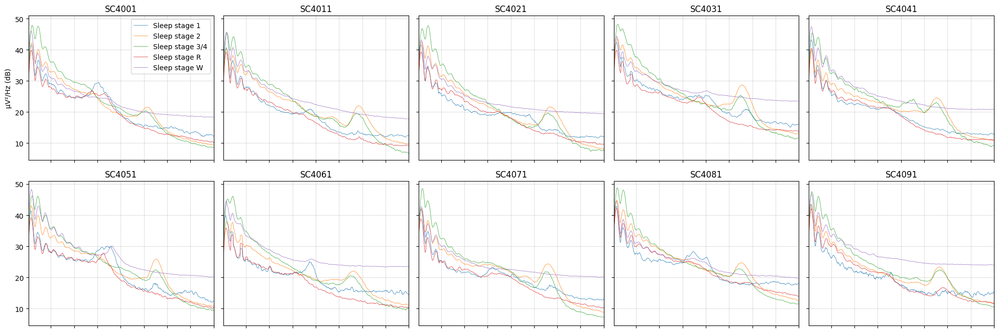

In [31]:
titles = [os.path.basename(psg)[:6] for psg, hyp in data]   # e.g. SC4001 = subject 00, night 1

fig, axes = plt.subplots(nrows=3, ncols=5, figsize=(20, 10), sharex=True, sharey=True)
axes = axes.flatten()

stages = sorted(event_id.keys())

for ax, title, epochs in zip(axes, titles, epochs_train):
    for stage, colour in zip(stages, stage_Colours):
        spectrum = epochs[stage].compute_psd(fmin=0.1, fmax=20.0)
        spectrum.plot(
            ci=None,
            color=colour,
            axes=ax,
            show=False,
            average=True,
            amplitude=False,
            spatial_colors=False,
            picks="data",
            exclude="bads",
        )
    ax.set_title(title)

for ax in axes[len(epochs_train):]:   # hide unused panels
    ax.set_visible(False)

axes[0].set(ylabel="µV²/Hz (dB)")
axes[0].legend(axes[0].lines[2::3], stages)
plt.tight_layout()
plt.show()

In [32]:
def eeg_power_band(epochs):
    FREQ_BANDS = {
        "delta":[0.5,4.5],
        "theta": [4.5,8.5],
        "alpha": [8.5, 11.5],
        "sigma": [11.5, 15.5],
        "beta": [15.5, 30.0],
    }   

    spectrum = epochs.compute_psd(picks="eeg", fmin=0.5,fmax=30.0)

    psds,freqs = spectrum.get_data(return_freqs=True)

    psds/= np.sum(psds,axis=-1,keepdims=True)

    X= []
    for fmin,fmax in FREQ_BANDS.values():
        psds_band = psds[:,:,(freqs>=fmin)& (freqs<fmax)].mean(axis=-1)
        X.append(psds_band.reshape(len(psds),-1))

    return np.concatenate(X,axis=-1)

In [35]:
epochs_train = mne.concatenate_epochs(epochs_train)
epochs_test = mne.concatenate_epochs(epochs_test)

Loading data for 1689 events and 3000 original time points ...


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/775927080.py:1: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  epochs_train = mne.concatenate_epochs(epochs_train)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/775927080.py:1: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  epochs_train = mne.concatenate_epochs(epochs_train)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/775927080.py:1: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  epochs_train = mne.concatenate_epochs(epochs_train)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykerne

0 bad epochs dropped
Loading data for 2144 events and 3000 original time points ...


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/775927080.py:1: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  epochs_train = mne.concatenate_epochs(epochs_train)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/775927080.py:1: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  epochs_train = mne.concatenate_epochs(epochs_train)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/775927080.py:1: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  epochs_trai

0 bad epochs dropped
Loading data for 2135 events and 3000 original time points ...


...

Loading data for 1783 events and 3000 original time points ...


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/775927080.py:2: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  epochs_test = mne.concatenate_epochs(epochs_test)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/775927080.py:2: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  epochs_test = mne.concatenate_epochs(epochs_test)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/775927080.py:2: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  epochs_test = m

Loading data for 1912 events and 3000 original time points ...


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/775927080.py:2: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  epochs_test = mne.concatenate_epochs(epochs_test)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/775927080.py:2: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  epochs_test = mne.concatenate_epochs(epochs_test)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_15593/775927080.py:2: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  epochs_test = m

Not setting metadata
7478 matching events found
No baseline correction applied


In [36]:
epochs_train

<EpochsArray | 19148 events (all good), 0 – 29.99 s (baseline off), ~3.00 GiB, data loaded,
 'Sleep stage W': 10995
 'Sleep stage 1': 764
 'Sleep stage 2': 4312
 'Sleep stage 3/4': 1483
 'Sleep stage R': 1594>

In [37]:
pipeline = make_pipeline(
    FunctionTransformer(eeg_power_band, validate=False),
    RandomForestClassifier(n_estimators=100, random_state=42),
)

y_train = epochs_train.events[:,2]

pipeline.fit(epochs_train,y_train)

y_pred = pipeline.predict(epochs_test)

y_test = epochs_test.events[:,2]

acc = accuracy_score(y_test,y_pred)

print(f"Test accuracy: {acc}")

    Using multitaper spectrum estimation with 7 DPSS windows
    Using multitaper spectrum estimation with 7 DPSS windows
Test accuracy: 0.8364535972185076


In [38]:
print(confusion_matrix(y_test, y_pred))

[[3629  106  175   11   57]
 [  60   33   55    0   35]
 [  85   37 1798  134   79]
 [   9    4   36  340    0]
 [  39   92  207    2  455]]


In [39]:
print(classification_report(y_test, y_pred, target_names=event_id.keys()))

                 precision    recall  f1-score   support

  Sleep stage W       0.95      0.91      0.93      3978
  Sleep stage 1       0.12      0.18      0.15       183
  Sleep stage 2       0.79      0.84      0.82      2133
Sleep stage 3/4       0.70      0.87      0.78       389
  Sleep stage R       0.73      0.57      0.64       795

       accuracy                           0.84      7478
      macro avg       0.66      0.68      0.66      7478
   weighted avg       0.85      0.84      0.84      7478

